# 📧 Task 4 · Email Spam Detection with Machine Learning

**Oasis Infobyte Internship (OIBSIP) · Data Science Track**
**Intern:** Vinay Singh Chaudhary  |  **Batch:** 5 Oct – 15 Nov 2026

---

### 🎯 Objective
Build a **Natural Language Processing (NLP) binary classifier** that separates **spam** messages from legitimate **ham** messages.

### 📦 Dataset — *SMS Spam Collection* (UCI ML Repository / Kaggle) → `data/spam.csv`
5,572 English messages labelled `ham` or `spam`. Columns: `v1` = label, `v2` = message text (plus 3 almost-empty spill-over columns).

### 🗺️ Workflow
Load → Clean columns & duplicates → Class distribution → Text preprocessing (lowercase, punctuation, stopwords, stemming) →
TF-IDF features → Split → Multinomial Naive Bayes + Logistic Regression + Linear SVM → Accuracy / Precision / Recall / F1 / Confusion matrix →
Why recall matters → WordClouds (bonus) → Try your own message

## 1️⃣ Setup

In [1]:
import os
import re
import html
import string
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.stem import PorterStemmer                         # stemming works offline (no download needed)
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)

# Stop-word list: use NLTK's list if it can be downloaded, otherwise fall back to scikit-learn's built-in list
try:
    import nltk
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    STOP_WORDS = set(stopwords.words("english"))
    print("✅ Using NLTK stop-words:", len(STOP_WORDS))
except Exception:
    STOP_WORDS = set(ENGLISH_STOP_WORDS)
    print("✅ NLTK stop-words unavailable offline → using scikit-learn list:", len(STOP_WORDS))

✅ NLTK stop-words unavailable offline → using scikit-learn list: 318


[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


## 2️⃣ Load the dataset
The file is **Latin-1 encoded** (it contains characters such as `£`), so we pass `encoding="latin-1"`.

In [2]:
raw = pd.read_csv("data/spam.csv", encoding="latin-1")
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
print("\nNon-null count per column:\n", raw.notnull().sum())
raw.head()

Shape: (5572, 5)
Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Non-null count per column:
 v1            5572
v2            5572
Unnamed: 2      50
Unnamed: 3      12
Unnamed: 4       6
dtype: int64


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
# Keep only the two useful columns and give them clear names
df = raw[["v1", "v2"]].rename(columns={"v1": "label", "v2": "message"})

# Remove exact duplicate messages — otherwise the same text could land in both train and test (data leakage)
before = len(df)
df = df.drop_duplicates(subset="message").reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate messages → {len(df)} unique messages")

# Numeric target: spam = 1, ham = 0
df["target"] = (df["label"] == "spam").astype(int)
df.head()

Removed 403 duplicate messages → 5169 unique messages


,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 3️⃣ Class distribution (spam vs ham)

,count,percentage (%)
label,,
ham,4516,87.37
spam,653,12.63


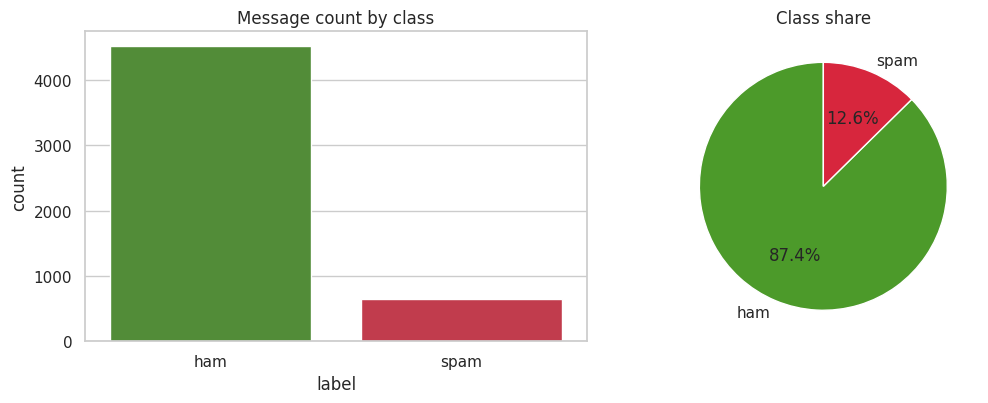

In [4]:
counts = df["label"].value_counts()
perc = df["label"].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({"count": counts, "percentage (%)": perc}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.countplot(data=df, x="label", hue="label", palette=["#4C9A2A", "#D7263D"], ax=axes[0], legend=False)
axes[0].set_title("Message count by class")
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["#4C9A2A", "#D7263D"], startangle=90)
axes[1].set_title("Class share")
plt.tight_layout()
plt.savefig("outputs/01_class_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

> **Observation:** The data is **imbalanced — ≈ 87 % ham vs ≈ 13 % spam**. A dumb model that always says "ham" would already get 87 % accuracy,
> so **accuracy alone is misleading**; we must look at precision, recall and F1 for the spam class.

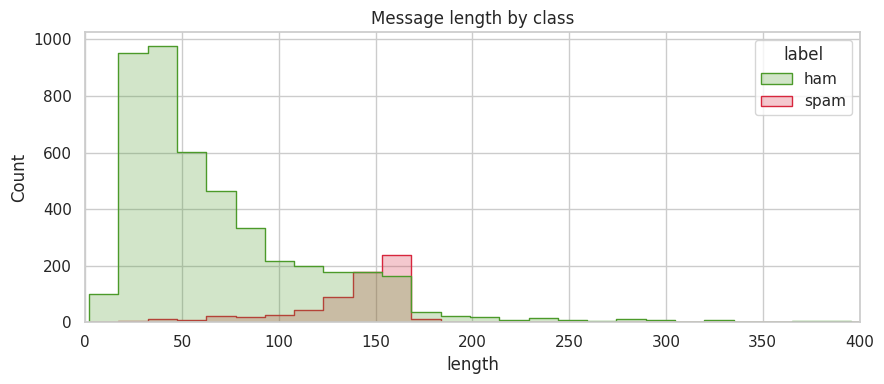

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4516.0,70.5,56.4,2.0,34.0,52.0,90.0,910.0
spam,653.0,137.9,30.1,13.0,132.0,149.0,157.0,224.0


In [5]:
# Quick extra insight: are spam messages longer?
df["length"] = df["message"].str.len()
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="length", hue="label", bins=60, element="step", palette=["#4C9A2A", "#D7263D"])
plt.title("Message length by class")
plt.xlim(0, 400)
plt.tight_layout()
plt.savefig("outputs/02_message_length.png", dpi=120, bbox_inches="tight")
plt.show()
df.groupby("label")["length"].describe().round(1)

> **Observation:** Spam messages are typically **longer (median ≈ 150 characters)** than ham (≈ 50) — they pack in offers, prices and phone numbers.

## 4️⃣ Text preprocessing pipeline
| Step | Why |
|------|-----|
| **Lowercase** | `FREE`, `Free`, `free` become one token |
| **Replace URLs / money symbols / numbers** with placeholder tokens | keeps the *signal* ("contains a phone number") while dropping unique values |
| **Remove punctuation** | `win!!!` → `win` |
| **Remove stop-words** | drop filler words (`the`, `is`, `and`) that appear in both classes |
| **Porter stemming** | `winning`, `wins`, `won` → `win` — reduces vocabulary size |

In [6]:
stemmer = PorterStemmer()
PUNCT_TABLE = str.maketrans("", "", string.punctuation)


def preprocess(text: str) -> str:
    """Clean one message and return a space-separated string of stemmed tokens."""
    text = html.unescape(text).lower()                                    # 1. decode '&lt;' etc. + lowercase
    text = re.sub(r"(https?://\S+|www\.\S+)", " urltoken ", text)         # 2a. URLs → placeholder
    text = re.sub(r"[£$€]", " moneytoken ", text)                         # 2b. currency symbols → placeholder
    text = re.sub(r"\d+", " numtoken ", text)                             # 2c. numbers → placeholder
    text = text.translate(PUNCT_TABLE)                                    # 3. remove punctuation
    text = re.sub(r"[^a-z\s]", " ", text)                                 # 3b. drop leftover non-English symbols (encoding noise)
    tokens = [w for w in text.split() if w not in STOP_WORDS and len(w) > 1]   # 4. stop-words & 1-letter tokens
    return " ".join(stemmer.stem(w) for w in tokens)                      # 5. stemming


df["clean"] = df["message"].apply(preprocess)
pd.set_option("display.max_colwidth", 90)
df[["label", "message", "clean"]].head(6)

,label,message,clean
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...",jurong point crazi avail bugi great world la buffet cine got amor wat
1,ham,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,free entri numtoken wkli comp win fa cup final tkt numtoken st numtoken text fa numtok...
3,ham,U dun say so early hor... U c already then say...,dun say earli hor say
4,ham,"Nah I don't think he goes to usf, he lives around here though",nah dont think goe usf live
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun y...,freemsg hey darl numtoken week word id like fun tb ok xxx std chg send moneytoken numt...


## 5️⃣ Feature extraction — TF-IDF

**What does TF-IDF measure?**
TF-IDF (*Term Frequency – Inverse Document Frequency*) scores how **important a word is to one message relative to the whole collection**:

* **TF (term frequency)** — how often word *t* appears in message *d*. Frequent words in a message matter more *for that message*.
* **IDF (inverse document frequency)** — $\text{idf}(t) = \log\frac{1 + N}{1 + \text{df}(t)} + 1$, where *N* = number of messages and df(*t*) = messages containing *t*.
  Words that appear everywhere ("call", "ok") get a **low** weight; rare, distinctive words ("prize", "claim") get a **high** weight.
* **TF-IDF = TF × IDF**, then each message vector is L2-normalised, so long and short messages are comparable.

Result: every message becomes a numeric vector where the largest values belong to the words that **best characterise** it —
exactly what a classifier needs. We use unigrams + bigrams (`"free entri"`, `"call numtoken"`) to capture short phrases.

In [7]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean"], df["target"], test_size=0.2, random_state=RANDOM_STATE, stratify=df["target"])

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(X_train_txt)      # learn vocabulary + IDF from TRAINING data only
X_test = tfidf.transform(X_test_txt)            # re-use it for the test data (no leakage)

print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
print("Vocabulary size (features):", X_train.shape[1])
print("Spam share → train: {:.1%}, test: {:.1%}".format(y_train.mean(), y_test.mean()))

Train size: 4135 | Test size: 1034
Vocabulary size (features): 5309
Spam share → train: 12.6%, test: 12.7%


## 6️⃣ Train the classifiers
* **Multinomial Naive Bayes** — the industry-standard baseline for text: fast, works well with word-frequency features.
* **Logistic Regression** — linear model, gives probabilities; `class_weight="balanced"` compensates for the 87/13 imbalance.
* **Linear SVM** — strong linear classifier for high-dimensional sparse text.

In [8]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=10, class_weight="balanced"),
    "Linear SVM": LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision (spam)": precision_score(y_test, pred),
                 "Recall (spam)": recall_score(y_test, pred),
                 "F1 (spam)": f1_score(y_test, pred)})

results = pd.DataFrame(rows).sort_values("F1 (spam)", ascending=False).reset_index(drop=True)
results.round(4)

,Model,Accuracy,Precision (spam),Recall (spam),F1 (spam)
0,Linear SVM,0.9845,0.9389,0.9389,0.9389
1,Multinomial Naive Bayes,0.9836,0.9672,0.9008,0.9328
2,Logistic Regression,0.9826,0.9248,0.9389,0.9318


## 7️⃣ Evaluation — classification reports & confusion matrices

In [9]:
for name, model in models.items():
    print("=" * 62, f"\n📋 {name}\n" + "=" * 62)
    print(classification_report(y_test, model.predict(X_test), target_names=["ham", "spam"], digits=3))

📋 Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham      0.986     0.996     0.991       903
        spam      0.967     0.901     0.933       131

    accuracy                          0.984      1034
   macro avg      0.976     0.948     0.962      1034
weighted avg      0.983     0.984     0.983      1034

📋 Logistic Regression
              precision    recall  f1-score   support

         ham      0.991     0.989     0.990       903
        spam      0.925     0.939     0.932       131

    accuracy                          0.983      1034
   macro avg      0.958     0.964     0.961      1034
weighted avg      0.983     0.983     0.983      1034

📋 Linear SVM
              precision    recall  f1-score   support

         ham      0.991     0.991     0.991       903
        spam      0.939     0.939     0.939       131

    accuracy                          0.985      1034
   macro avg      0.965     0.965     0.965      1034
weighted avg 

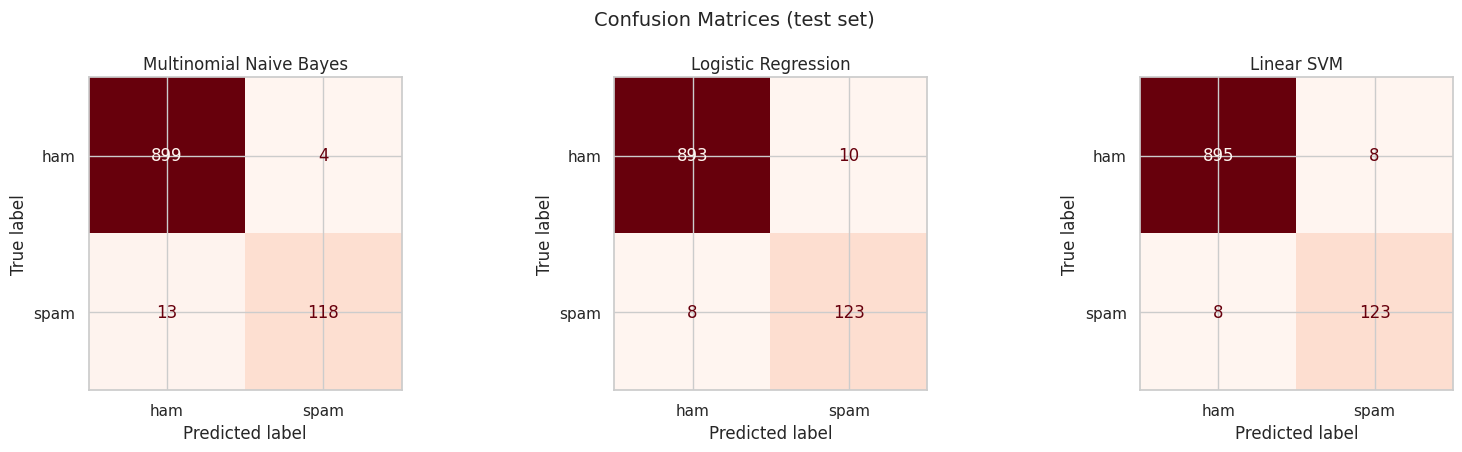

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["ham", "spam"],
                                          cmap="Reds", colorbar=False, ax=ax)
    ax.set_title(name)
plt.suptitle("Confusion Matrices (test set)", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/03_confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

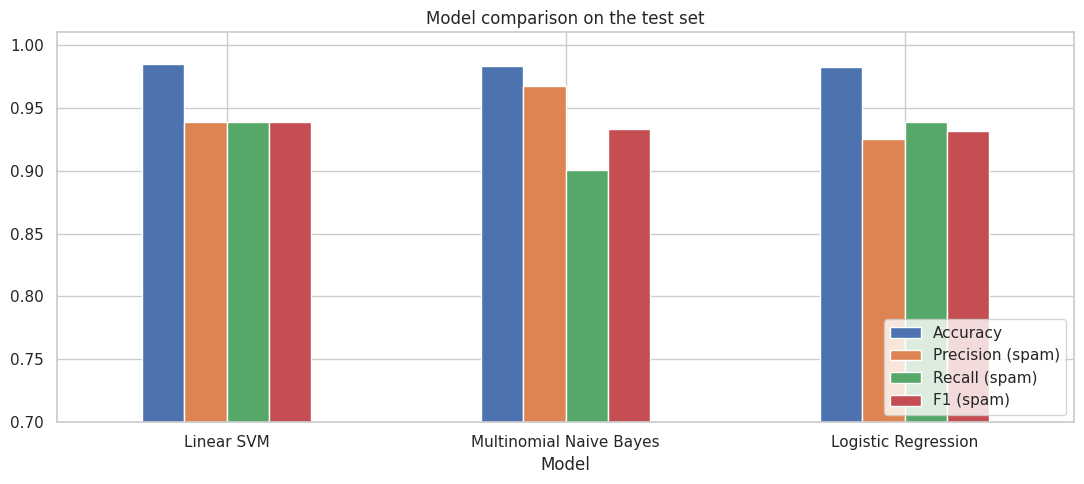

In [11]:
ax = results.set_index("Model")[["Accuracy", "Precision (spam)", "Recall (spam)", "F1 (spam)"]].plot(
    kind="bar", figsize=(11, 5), rot=0)
ax.set_ylim(0.7, 1.01)
ax.set_title("Model comparison on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("outputs/04_model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

In [12]:
# Robustness check: 5-fold cross-validated F1 (vectoriser re-fitted inside each fold via a Pipeline)
from sklearn.pipeline import make_pipeline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), model)
    scores = cross_val_score(pipe, df["clean"], df["target"], cv=cv, scoring="f1")
    print(f"{name:25s} CV F1 = {scores.mean():.3f} ± {scores.std():.3f}")

Multinomial Naive Bayes   CV F1 = 0.936 ± 0.007


Logistic Regression       CV F1 = 0.933 ± 0.016


Linear SVM                CV F1 = 0.941 ± 0.018


## 8️⃣ Discussion — why is **recall** particularly important for spam detection?

**Recall (spam)** = *of all real spam messages, how many did we catch?* = TP / (TP + FN).

* A **false negative** (spam that slips into the inbox) is the failure users actually notice — and spam is not just annoying:
  it carries **phishing links, fraud ("you won ₹10 lakh, send your bank details") and malware**. Every missed spam is a potential security incident.
* Because spam is only ~13 % of the data, a model can have high accuracy while missing a large share of spam — recall exposes that weakness.
* Therefore we want recall **as high as possible**.

**But not at any price:** a **false positive** (a real message sent to the spam folder — e.g. a job offer or OTP) is also costly.
So in practice we optimise **recall while keeping precision high**, which is why we also report **F1** and why production filters
usually send suspected spam to a *junk folder* (recoverable) instead of deleting it.

**Model choice:** Naive Bayes delivers the best **precision** (it almost never flags a ham message as spam),
while the class-weighted **Linear SVM / Logistic Regression catch more spam (higher recall)** — the best overall F1 is shown in the table above.

In [13]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
print(f"🏆 Best model by spam-F1: {best_name}")
print(results.loc[0].drop("Model").astype(float).round(4).to_string())

🏆 Best model by spam-F1: Linear SVM
Accuracy            0.9845
Precision (spam)    0.9389
Recall (spam)       0.9389
F1 (spam)           0.9389


### 8.1 Trading precision for recall — adjusting Naive Bayes' decision threshold
By default a message is called spam when P(spam) ≥ 0.5. Lowering the threshold catches more spam (↑ recall) at the cost of a few
more false alarms (↓ precision). This is how a business would tune the filter to its own risk appetite.

In [14]:
nb_proba = models["Multinomial Naive Bayes"].predict_proba(X_test)[:, 1]
rows_t = []
for thr in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred_t = (nb_proba >= thr).astype(int)
    rows_t.append({"Threshold": thr, "Precision": precision_score(y_test, pred_t),
                   "Recall": recall_score(y_test, pred_t), "F1": f1_score(y_test, pred_t),
                   "Spam missed (FN)": int(((pred_t == 0) & (y_test == 1)).sum()),
                   "Ham flagged (FP)": int(((pred_t == 1) & (y_test == 0)).sum())})
pd.DataFrame(rows_t).round(3)

,Threshold,Precision,Recall,F1,Spam missed (FN),Ham flagged (FP)
0,0.5,0.967,0.901,0.933,13,4
1,0.4,0.961,0.931,0.946,9,5
2,0.3,0.947,0.962,0.955,5,7
3,0.2,0.926,0.962,0.944,5,10
4,0.1,0.723,0.977,0.831,3,49


> **Observation:** Lowering the threshold from 0.5 to **0.3** cuts missed spam from **13 → 5** while only 3 more genuine messages are flagged —
> recall rises to ≈ 96 % with precision still ≈ 95 %, and F1 improves. Going lower (0.1) floods the junk folder with real messages. **0.3 is the sweet spot.**

## 9️⃣ (Bonus) WordClouds — most frequent words in spam vs ham

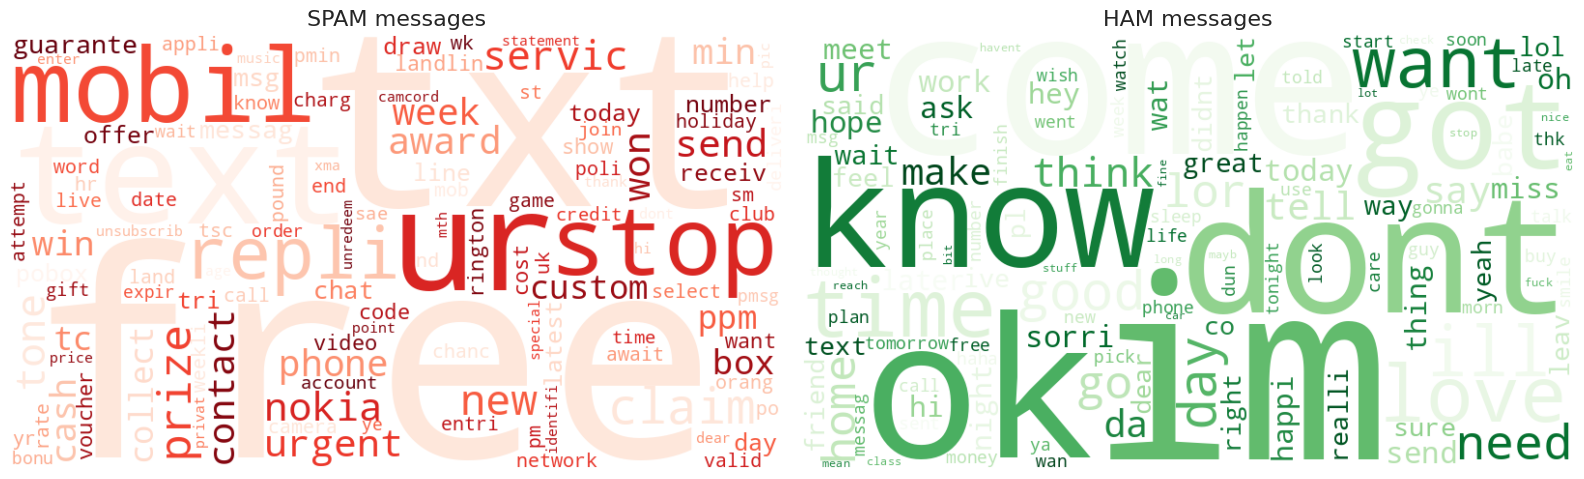

In [15]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, label, cmap in zip(axes, ["spam", "ham"], ["Reds", "Greens"]):
    text = " ".join(df.loc[df["label"] == label, "clean"]).replace("numtoken", "").replace("urltoken", "").replace("moneytoken", "")
    wc = WordCloud(width=800, height=450, background_color="white", colormap=cmap,
                   max_words=120, collocations=False, random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"{label.upper()} messages", fontsize=16)
    ax.axis("off")
plt.tight_layout()
plt.savefig("outputs/05_wordclouds.png", dpi=120, bbox_inches="tight")
plt.show()

> **Observation:** Spam is dominated by **free, txt/text, mobil(e), stop, repli, claim, prize, won, urgent, award** — urgency + reward + a call to action.
> Ham is conversational: **ok, know, dont, come, got, want, love, time, think**.

In [16]:
# Words with the strongest pull towards "spam" according to the Logistic Regression model
lr = models["Logistic Regression"]
coef = pd.Series(lr.coef_[0], index=tfidf.get_feature_names_out())
print("Top 15 spam indicators:\n", coef.sort_values(ascending=False).head(15).round(2).to_string())

Top 15 spam indicators:
 urltoken               10.48
numtoken                9.32
numtoken numtoken       6.99
txt                     6.53
text                    6.43
moneytoken              6.10
repli                   6.04
mobil                   5.96
moneytoken numtoken     5.65
servic                  5.40
rington                 4.56
divorc                  4.49
claim                   4.44
arsen                   4.39
new                     4.32


## 🔟 Try it on new messages

In [17]:
def predict_message(msg: str) -> str:
    vec = tfidf.transform([preprocess(msg)])
    return "🚫 SPAM" if best_model.predict(vec)[0] == 1 else "✅ HAM"


samples = [
    "Congratulations! You have WON a free iPhone. Call 09061701461 now to claim your prize!",
    "Hey, are we still meeting for lunch at 1 pm tomorrow?",
    "URGENT: Your account will be suspended. Verify at www.secure-bank-login.com within 24 hours",
    "Can you send me the notes from today's class please?",
]
for m in samples:
    print(f"{predict_message(m):8s} ← {m}")

🚫 SPAM   ← Congratulations! You have WON a free iPhone. Call 09061701461 now to claim your prize!
✅ HAM    ← Hey, are we still meeting for lunch at 1 pm tomorrow?
🚫 SPAM   ← URGENT: Your account will be suspended. Verify at www.secure-bank-login.com within 24 hours
✅ HAM    ← Can you send me the notes from today's class please?


## ✅ Conclusions
- 5,169 unique messages (≈ 13 % spam) were cleaned with a full NLP pipeline and converted to TF-IDF features (uni + bi-grams).
- All three models exceed **97 % accuracy**; the real differences show in spam **recall vs precision**.
- **Naive Bayes** is the most precise (very few genuine messages lost); **class-weighted linear models** catch more spam.
- Recall is critical because every missed spam can be a phishing or fraud attempt — balanced against precision so real messages are not lost.
- Tuning Naive Bayes' threshold to **0.3** raises spam recall from ≈ 90 % to ≈ 96 % with precision still ≈ 95 %.

**Future scope:** try transformer models (DistilBERT), deploy as an email/SMS filter API.

---
*Submitted by **Vinay Singh Chaudhary** for the Oasis Infobyte Data Science Internship · #oasisinfobyte*